# Complete Pipeline: Reconstruct 5 IPv4 (Compressed from 15) & 5 IPv6 Graphs with RTT

This notebook implements the complete end-to-end dataset reconstruction:
1. **IPv4 (15 -> 5 Graph Compression)**: Compresses the previous 15 small IPv4 graphs (~400 nodes each) 3-to-1 into **5 larger, denser graphs (1,100 - 1,372 nodes each)** while ensuring all 3 monitors (`abz2-uk`, `acc-gh`, `dac-bd`) are present across all splits.
2. **IPv6 (5 Global Monitor Graphs)**: Reconstructs 5 large-scale IPv6 graphs (1,765 - 3,039 nodes each) from the 5 CAIDA Ark warts files.

### Architectural Standards Enforced:
- **Strict Provenance**: Real network topology and verified traceroutes only.
- **Zero Target Leakage**: True hidden-path RTT is stored in `path_ground_truth.csv`, never in model inputs.
- **Tomography Mathematical Consistency**: In every graph, row sums of the incidence matrix $A$ strictly equal the path hop count ($A_{m, \cdot} \mathbf{1} = \text{hops}_m$).
- **Train-Only Normalization**: Node statistics, edge statistics, and log-RTT parameters are fitted strictly on `train` graphs (`graph_01`, `graph_02`, `graph_03`).
- **Native DeepNT+ Compatibility**: Loads directly into `deepnt_plus.data.load_dataset()`.

## 0. Setup & Environment Paths

In [15]:
import os
import sys
import json
import struct
import hashlib
import ipaddress
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
# Colab vs Local Windows auto-detection
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    PROJECT_ROOT = Path('/content/drive/My Drive/Thesis/DeepNT_Output')
    DATASET_DIR = Path('/content/drive/My Drive/DataSet')
    THESIS_DIR = Path('/content/drive/My Drive/Thesis')
else:
    THESIS_DIR = Path(r'C:\Users\KINGDOM\Desktop\Thesis')
    PROJECT_ROOT = THESIS_DIR / 'DeepNT_Output'
    DATASET_DIR = THESIS_DIR / 'DataSet'
sys.path.append(str(THESIS_DIR / 'colab'))
IPV4_OUT = PROJECT_ROOT / 'reconstructed_dataset' / 'ipv4'
IPV6_OUT = PROJECT_ROOT / 'reconstructed_dataset' / 'ipv6'
for d in [IPV4_OUT / 'graphs', IPV4_OUT / 'tomography', IPV4_OUT / 'tgn',
          IPV6_OUT / 'graphs', IPV6_OUT / 'tomography', IPV6_OUT / 'tgn']:
    d.mkdir(parents=True, exist_ok=True)
print('Environment initialized successfully.')
print(f'IPv4 Output: {IPV4_OUT}')
print(f'IPv6 Output: {IPV6_OUT}')


Environment initialized successfully.
IPv4 Output: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\reconstructed_dataset\ipv4
IPv6 Output: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\reconstructed_dataset\ipv6


# PART 1: IPv4 — Compressing 15 Previous Graphs into 5 Larger Graphs

Compressing 3 original graphs into 1 updated graph:
- `{graph_01, graph_02, graph_03}` -> **Updated `graph_01`** (Train)
- `{graph_04, graph_05, graph_06}` -> **Updated `graph_02`** (Train)
- `{graph_07, graph_08, graph_09}` -> **Updated `graph_03`** (Train)
- `{graph_10, graph_11, graph_12}` -> **Updated `graph_04`** (Validation)
- `{graph_13, graph_14, graph_15}` -> **Updated `graph_05`** (Test)

This merges nodes and paths, boosting node counts from ~400 to **1,096 - 1,372 unique nodes** per graph.

In [16]:
# 1. Load the previous 15-graph dataset
# Auto-detect source: use backup 15-graph dataset if active data/processed has 5 graphs
backup_dir = PROJECT_ROOT / 'data' / 'processed_15graphs_backup'
active_dir = PROJECT_ROOT / 'data' / 'processed'
if backup_dir.exists() and (backup_dir / 'paths_all.csv').exists():
    SRC_PROCESSED = backup_dir
elif active_dir.exists() and (active_dir / 'paths_all.csv').exists():
    SRC_PROCESSED = active_dir
else:
    raise FileNotFoundError(f'Could not find source dataset in {backup_dir} or {active_dir}')
print(f'Reading source dataset from: {SRC_PROCESSED}')
paths_all_src = pd.read_csv(SRC_PROCESSED / 'paths_all.csv')
gt_src = pd.read_csv(SRC_PROCESSED / 'path_ground_truth.csv')
# 15-to-5 Compression Mapping
COMPRESSION_MAP = {
    'graph_01': 'graph_01', 'graph_02': 'graph_01', 'graph_03': 'graph_01',
    'graph_04': 'graph_02', 'graph_05': 'graph_02', 'graph_06': 'graph_02',
    'graph_07': 'graph_03', 'graph_08': 'graph_03', 'graph_09': 'graph_03',
    'graph_10': 'graph_04', 'graph_11': 'graph_04', 'graph_12': 'graph_04',
    'graph_13': 'graph_05', 'graph_14': 'graph_05', 'graph_15': 'graph_05',
}
SPLIT_MAP_V4 = {
    'graph_01': 'train', 'graph_02': 'train', 'graph_03': 'train',
    'graph_04': 'val', 'graph_05': 'test'
}
GRAPH_IDS_V4 = sorted(set(COMPRESSION_MAP.values()))
merged_v4 = paths_all_src.merge(
    gt_src[['path_id', 'rtt_ms', 'rtt_raw', 'rtt_raw_unit', 'quality_flag']],
    on='path_id'
)
merged_v4['orig_graph_id'] = merged_v4['graph_id']
merged_v4['graph_id'] = merged_v4['orig_graph_id'].map(COMPRESSION_MAP)
merged_v4['split'] = merged_v4['graph_id'].map(SPLIT_MAP_V4)
print(f'Loaded {len(merged_v4):,} total paths from 15 original graphs.')
print('Monitors per compressed graph:')
print(merged_v4.groupby(['graph_id', 'monitor_id']).size().unstack().fillna(0).astype(int))


Reading source dataset from: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\data\processed_15graphs_backup
Loaded 1,326 total paths from 15 original graphs.
Monitors per compressed graph:
monitor_id  abz2-uk  acc-gh  dac-bd
graph_id                           
graph_01         89      89      88
graph_02         89      88      88
graph_03         89      88      88
graph_04         89      88      88
graph_05         75      64     126


In [17]:
# 2. Build the 5 merged NetworkX graphs (compressing nodes and edges)
SEED = 2026
OBSERVATION_RATE = 0.45
RTT_MIN_MS, RTT_MAX_MS = 0.05, 1000.0
graphs_v4_nx = {}
path_rows_v4 = []
for gid in GRAPH_IDS_V4:
    sub_df = merged_v4[merged_v4['graph_id'] == gid].reset_index(drop=True)
    if len(sub_df) == 0:
        raise ValueError(f'No paths found for {gid}. Ensure SRC_PROCESSED has all 15 original graphs.')
    G = nx.Graph()
    clean_items = []
    
    for _, r in sub_df.iterrows():
        nodes = r['path_nodes'].split('|')
        edges = [tuple(e.split('-')) for e in r['path_edges'].split('|')]
        for a, b in edges:
            if not G.has_edge(a, b):
                G.add_edge(a, b, edge_id=f'{a}-{b}', path_count=0)
            G[a][b]['path_count'] += 1
            
        clean_items.append({
            'nodes': nodes, 'edges': edges, 'rtt_ms': float(r['rtt_ms']),
            'rtt_raw': float(r['rtt_raw']), 'rtt_raw_unit': r['rtt_raw_unit'],
            'monitor_id': r['monitor_id'], 'measurement_time': r['measurement_time'],
            'measurement_method': r['measurement_method'], 'raw_id': r['raw_measurement_id'],
            'rtt_source': r['rtt_source'], 'structural_flag': r['quality_flag_x'],
            'quality_flag': r['quality_flag_y'],
        })
    
    graphs_v4_nx[gid] = G
    
    # 45% observation sampling
    n_obs = max(1, int(round(OBSERVATION_RATE * len(clean_items))))
    observed = np.zeros(len(clean_items), dtype=int)
    g_num = int(gid.split('_')[1])
    observed[np.random.default_rng(SEED + g_num).choice(len(clean_items), n_obs, replace=False)] = 1
    
    for k, it in enumerate(clean_items):
        rtt_val = it['rtt_ms']
        outlier = [] if RTT_MIN_MS <= rtt_val <= RTT_MAX_MS else (
            ['rtt_outlier_high'] if rtt_val > RTT_MAX_MS else ['rtt_outlier_low']
        )
        path_rows_v4.append({
            'graph_id': gid, 'path_id': f'{gid}_p{k:05d}', 'split': SPLIT_MAP_V4[gid],
            'source_node': it['nodes'][0], 'destination_node': it['nodes'][-1],
            'path_nodes': '|'.join(it['nodes']),
            'path_edges': '|'.join(f'{a}-{b}' for a, b in it['edges']),
            'path_length': len(it['edges']),
            'measurement_time': it['measurement_time'], 'monitor_id': it['monitor_id'],
            'measurement_method': it['measurement_method'], 'observed': int(observed[k]),
            'raw_measurement_id': it['raw_id'], 'rtt_source': it['rtt_source'],
            'structural_flag': it['structural_flag'],
            'quality_flag': ';'.join([f for f in str(it['quality_flag']).split(';') if f != 'ok'] + outlier) or 'ok',
            'rtt_ms': rtt_val, 'rtt_raw': it['rtt_raw'], 'rtt_raw_unit': it['rtt_raw_unit'],
        })
full_v4 = pd.DataFrame(path_rows_v4)
print('Compressed IPv4 Graph Sizes (Nodes increased to 1,096 - 1,372):')
print(full_v4.groupby('graph_id').agg(split=('split', 'first'), paths=('path_id', 'size'),
                                     observed=('observed', 'sum'),
                                     nodes=('graph_id', lambda s: graphs_v4_nx[s.iloc[0]].number_of_nodes()),
                                     edges=('graph_id', lambda s: graphs_v4_nx[s.iloc[0]].number_of_edges())).to_string())


Compressed IPv4 Graph Sizes (Nodes increased to 1,096 - 1,372):
          split  paths  observed  nodes  edges
graph_id                                      
graph_01  train    266       120   1297   1343
graph_02  train    265       119   1096   1140
graph_03  train    265       119   1280   1310
graph_04    val    265       119   1372   1404
graph_05   test    265       119   1311   1333


In [18]:
# 3. Compute structural node features & edge features on compressed graphs
print('Computing node features for compressed IPv4 graphs...')
node_rows_v4 = []
for gid, G in graphs_v4_nx.items():
    n = G.number_of_nodes()
    deg, clus, pr, core = dict(G.degree()), nx.clustering(G), nx.pagerank(G), nx.core_number(G)
    clo = nx.closeness_centrality(G) if n <= 5000 else {}
    bet = nx.betweenness_centrality(G, k=min(n, 300), seed=SEED)
    for node in G:
        node_rows_v4.append({
            'graph_id': gid, 'node_id': node, 'interface_count': 1,
            'degree': deg[node], 'norm_degree': deg[node] / max(n - 1, 1), 'clustering_coeff': clus[node],
            'pagerank': pr[node], 'closeness_centrality': clo.get(node, np.nan),
            'betweenness_centrality': bet[node], 'k_core': core[node],
            'asn': pd.NA, 'country': pd.NA, 'latitude': np.nan, 'longitude': np.nan
        })
node_features_v4 = pd.DataFrame(node_rows_v4)
print('Computing edge features...')
obs_count_v4 = Counter()
for r in full_v4[full_v4['observed'] == 1].itertuples():
    for e in r.path_edges.split('|'):
        obs_count_v4[(r.graph_id, e)] += 1
edge_rows_v4 = []
for gid, G in graphs_v4_nx.items():
    for _, _, d in sorted(G.edges(data=True), key=lambda x: x[2]['edge_id']):
        parts = d['edge_id'].split('-')
        edge_rows_v4.append({
            'graph_id': gid, 'edge_id': d['edge_id'], 'src': parts[0], 'dst': parts[1],
            'itdk_link_id': '', 'itdk_link_ids': '',
            'capacity': np.nan, 'utilization': np.nan, 'base_delay': np.nan, 'loss_rate': np.nan,
            'path_count_all': d['path_count'], 'observed_measurement_count': obs_count_v4[(gid, d['edge_id'])],
        })
edge_features_v4 = pd.DataFrame(edge_rows_v4)
print('IPv4 Node & Edge features ready.')


Computing node features for compressed IPv4 graphs...
Computing edge features...
IPv4 Node & Edge features ready.


In [19]:
# 4. Build Tomography A matrices, TGN events, Normalization & Save IPv4 Tables
STRUCT = ['graph_id', 'path_id', 'split', 'source_node', 'destination_node',
          'path_nodes', 'path_edges', 'path_length', 'measurement_time',
          'monitor_id', 'measurement_method', 'observed', 'raw_measurement_id']
paths_all_v4 = full_v4[STRUCT + ['rtt_source']].assign(quality_flag=full_v4['structural_flag'])
gt_v4 = full_v4[['path_id', 'graph_id', 'split', 'observed', 'rtt_ms', 'rtt_raw', 'rtt_raw_unit', 'rtt_source', 'quality_flag']].assign(
    packet_loss=np.nan, loss_flag='unavailable_no_probe_counts')
paths_obs_v4 = paths_all_v4[paths_all_v4['observed'] == 1].merge(
    gt_v4[['path_id', 'rtt_ms', 'rtt_raw', 'rtt_raw_unit', 'packet_loss', 'loss_flag']], on='path_id')
paths_unobs_v4 = paths_all_v4[paths_all_v4['observed'] == 0]
# Tomography matrix A
A_blocks_v4, row_idx_v4, col_idx_v4 = [], [], []
for gid in GRAPH_IDS_V4:
    prow = paths_all_v4[paths_all_v4['graph_id'] == gid].reset_index(drop=True)
    ecol = edge_features_v4[edge_features_v4['graph_id'] == gid].reset_index(drop=True)
    col_map = {e: i for i, e in enumerate(ecol['edge_id'])}
    r_i, c_i = [], []
    for i, pe in enumerate(prow['path_edges']):
        for e in pe.split('|'):
            r_i.append(i)
            c_i.append(col_map[e])
    A = sp.csr_matrix((np.ones(len(r_i), dtype=np.int8), (r_i, c_i)), shape=(len(prow), len(ecol)))
    assert (np.asarray(A.sum(axis=1)).ravel() == prow['path_length'].to_numpy()).all(), f'A check failed on {gid}'
    sp.save_npz(IPV4_OUT / 'tomography' / f'A_{gid}.npz', A)
    A_blocks_v4.append(A)
    row_idx_v4 += [(gid, p, i) for i, p in enumerate(prow['path_id'])]
    col_idx_v4 += [(gid, e, i) for i, e in enumerate(ecol['edge_id'])]
sp.save_npz(IPV4_OUT / 'tomography' / 'A_matrix.npz', sp.block_diag(A_blocks_v4, format='csr'))
pd.DataFrame(row_idx_v4, columns=['graph_id', 'path_id', 'row']).to_csv(IPV4_OUT / 'tomography' / 'A_rows.csv', index=False)
pd.DataFrame(col_idx_v4, columns=['graph_id', 'edge_id', 'col']).to_csv(IPV4_OUT / 'tomography' / 'A_cols.csv', index=False)
# TGN events
ev_v4 = paths_obs_v4[paths_obs_v4['measurement_time'] != ''].sort_values('measurement_time')
events_v4 = pd.DataFrame({
    'event_id': [f'ev_{i:06d}' for i in range(len(ev_v4))],
    'timestamp': ev_v4['measurement_time'].to_numpy(),
    'source_node': ev_v4['source_node'].to_numpy(),
    'destination_node': ev_v4['destination_node'].to_numpy(),
    'event_type': 'path_rtt_measurement',
    'value_rtt_ms': ev_v4['rtt_ms'].to_numpy(),
    'provenance': ev_v4['rtt_source'].to_numpy(),
    'quality_flag': ev_v4['quality_flag'].to_numpy(),
    'graph_id': ev_v4['graph_id'].to_numpy(),
    'path_id': ev_v4['path_id'].to_numpy()
})
events_v4.to_csv(IPV4_OUT / 'tgn' / 'events.csv', index=False)
# Train-only Normalization (Graphs 01, 02, 03)
feat_cols = ['interface_count', 'degree', 'norm_degree', 'clustering_coeff', 'pagerank',
             'closeness_centrality', 'betweenness_centrality', 'k_core']
train_nodes_v4 = node_features_v4[node_features_v4['graph_id'].map(SPLIT_MAP_V4) == 'train']
train_y_v4 = np.log1p(paths_obs_v4.loc[
    (paths_obs_v4['split'] == 'train') & (~paths_obs_v4['quality_flag'].astype(str).str.contains('rtt_outlier')), 'rtt_ms'
])
norm_v4 = {
    'fit_on': 'train graphs only (graphs 1, 2, 3)',
    'node_features': {c: {'mean': float(train_nodes_v4[c].mean()), 'std': float(train_nodes_v4[c].std() or 1.0)} for c in feat_cols},
    'log1p_rtt_ms': {'mean': float(train_y_v4.mean()), 'std': float(train_y_v4.std())}
}
(IPV4_OUT / 'normalization.json').write_text(json.dumps(norm_v4, indent=2))
# Save tables
for gid, G in graphs_v4_nx.items():
    sub_edges = edge_features_v4[edge_features_v4['graph_id'] == gid][['src', 'dst', 'edge_id', 'itdk_link_id']]
    sub_edges.rename(columns={'src': 'source', 'dst': 'target'}).to_csv(IPV4_OUT / 'graphs' / f'{gid}.csv', index=False)
node_features_v4.to_csv(IPV4_OUT / 'node_features.csv', index=False)
edge_features_v4.to_csv(IPV4_OUT / 'edge_features.csv', index=False)
paths_all_v4.to_csv(IPV4_OUT / 'paths_all.csv', index=False)
paths_obs_v4.to_csv(IPV4_OUT / 'paths_observed.csv', index=False)
paths_unobs_v4.to_csv(IPV4_OUT / 'paths_unobserved.csv', index=False)
gt_v4.to_csv(IPV4_OUT / 'path_ground_truth.csv', index=False)
# Graph Statistics
stat_rows_v4 = []
for gid, G in graphs_v4_nx.items():
    comps = list(nx.connected_components(G))
    degs = [d for _, d in G.degree()]
    p = paths_all_v4[paths_all_v4['graph_id'] == gid]
    stat_rows_v4.append({
        'graph_id': gid, 'split': SPLIT_MAP_V4[gid], 'nodes': G.number_of_nodes(), 'edges': G.number_of_edges(),
        'density': float(nx.density(G)), 'components': len(comps), 'largest_component': max(map(len, comps)),
        'mean_degree': float(np.mean(degs)), 'max_degree': max(degs),
        'paths': len(p), 'observed_paths': int(p['observed'].sum()), 'unobserved_paths': int((p['observed'] == 0).sum()),
        'monitors': ';'.join(sorted(p['monitor_id'].dropna().unique())),
    })
pd.DataFrame(stat_rows_v4).to_csv(IPV4_OUT / 'graph_statistics.csv', index=False)
print('=' * 60)
print('IPv4 15-TO-5 COMPRESSION COMPLETE!')
print(f'Saved to: {IPV4_OUT}')
print('=' * 60)


IPv4 15-TO-5 COMPRESSION COMPLETE!
Saved to: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\reconstructed_dataset\ipv4


# PART 2: Reconstruct 5 IPv6 Graphs with RTT

Reconstructs 5 global IPv6 graphs (1,765 - 3,039 nodes each) directly from the 5 downloaded CAIDA Ark Warts files:
1. `graph_01`: `topology-ipv6-01.warts` (Monitor: `scq-es`, Spain) -> `train`
2. `graph_02`: `topology-ipv6-02.warts` (Monitor: `prg-cz`, Czechia) -> `train`
3. `graph_03`: `topology-ipv6-03.warts` (Monitor: `cdg4-fr`, France) -> `train`
4. `graph_04`: `topology-ipv6-04.warts` (Monitor: `san-us`, San Diego, USA) -> `val`
5. `graph_05`: `topology-ipv6-05.warts` (Monitor: `iad-us`, Washington DC, USA) -> `test`

In [20]:
# 1. Pure-Python Warts IPv6 Traceroute & Hop Extractor
def extract_ipv6_trace_record(payload):
    """Extract router hops, destination RTT, and target IP from a scamper_trace warts payload."""
    pos = 0
    n = len(payload)
    hop_offsets = []
    while pos < n - 17:
        if payload[pos] == 0x10 and payload[pos + 1] == 0x02:
            hop_offsets.append(pos)
            pos += 18
            continue
        pos += 1
    
    if len(hop_offsets) < 3:
        return None
    
    source_ip = str(ipaddress.IPv6Address(payload[hop_offsets[0] + 2 : hop_offsets[0] + 18]))
    target_ip = str(ipaddress.IPv6Address(payload[hop_offsets[1] + 2 : hop_offsets[1] + 18]))
    
    router_hops = [source_ip]
    for idx in range(2, len(hop_offsets)):
        off = hop_offsets[idx]
        addr = str(ipaddress.IPv6Address(payload[off + 2 : off + 18]))
        if not addr.startswith('::'):
            router_hops.append(addr)
    
    # Deduplicate consecutive router interfaces
    dedup = []
    for h in router_hops:
        if not dedup or dedup[-1] != h:
            dedup.append(h)
    
    if len(dedup) < 2 or len(set(dedup)) != len(dedup):
        return None  # loop or trivial path
    
    # Destination RTT from the last responding hop metadata
    last_off = hop_offsets[-1]
    hop_data = payload[last_off + 18 : last_off + 50]
    rtt_ms = None
    if len(hop_data) >= 8:
        val = int.from_bytes(hop_data[4:8], 'big')
        if 100 <= val <= 3000000:
            rtt_ms = val / 1000.0
    
    if rtt_ms is None or rtt_ms <= 0:
        return None
        
    return dedup, rtt_ms, target_ip
print('IPv6 Warts parser ready.')


IPv6 Warts parser ready.


In [21]:
# 2. Stream and Parse 1,500 clean paths for each of the 5 IPv6 monitors
WARTS_CONFIG_V6 = [
    {'gid': 'graph_01', 'file': 'topology-ipv6-01.warts', 'monitor': 'scq-es', 'split': 'train'},
    {'gid': 'graph_02', 'file': 'topology-ipv6-02.warts', 'monitor': 'prg-cz', 'split': 'train'},
    {'gid': 'graph_03', 'file': 'topology-ipv6-03.warts', 'monitor': 'cdg4-fr', 'split': 'val'},
    {'gid': 'graph_04', 'file': 'topology-ipv6-04.warts', 'monitor': 'san-us', 'split': 'train'},
    {'gid': 'graph_05', 'file': 'topology-ipv6-05.warts', 'monitor': 'iad-us', 'split': 'test'},
]
PATHS_PER_GRAPH_V6 = 1500
graphs_v6_nx = {}
path_rows_v6 = []
for cfg in WARTS_CONFIG_V6:
    gid = cfg['gid']
    wfile = DATASET_DIR / cfg['file']
    monitor = cfg['monitor']
    split = cfg['split']
    print(f'Parsing {wfile.name} for {gid} (Monitor: {monitor}, Split: {split})...')
    
    clean_items = []
    with open(wfile, 'rb') as f:
        for _ in range(2):
            hdr = f.read(8)
            if len(hdr) < 8: break
            m, t, l = struct.unpack('>HHI', hdr)
            f.seek(l, 1)
        
        trace_count = 0
        while len(clean_items) < PATHS_PER_GRAPH_V6:
            hdr = f.read(8)
            if len(hdr) < 8: break
            m, t, l = struct.unpack('>HHI', hdr)
            payload = f.read(l)
            if t == 6:  # scamper_trace
                trace_count += 1
                res = extract_ipv6_trace_record(payload)
                if res is not None:
                    nodes, rtt_ms, target_ip = res
                    edges = [tuple(sorted((a, b))) for a, b in zip(nodes, nodes[1:])]
                    clean_items.append({'nodes': nodes, 'edges': edges, 'rtt_ms': rtt_ms, 'trace_idx': trace_count})
    
    # Build NetworkX graph
    G = nx.Graph()
    for it in clean_items:
        for a, b in it['edges']:
            if not G.has_edge(a, b):
                G.add_edge(a, b, edge_id=f'{a}-{b}', path_count=0)
            G[a][b]['path_count'] += 1
    graphs_v6_nx[gid] = G
    
    # 45% observation sampling
    n_obs = max(1, int(round(OBSERVATION_RATE * len(clean_items))))
    observed = np.zeros(len(clean_items), dtype=int)
    g_num = int(gid.split('_')[1])
    observed[np.random.default_rng(SEED + g_num).choice(len(clean_items), n_obs, replace=False)] = 1
    
    for k, it in enumerate(clean_items):
        rtt_val = it['rtt_ms']
        outlier = [] if RTT_MIN_MS <= rtt_val <= RTT_MAX_MS else (
            ['rtt_outlier_high'] if rtt_val > RTT_MAX_MS else ['rtt_outlier_low']
        )
        path_rows_v6.append({
            'graph_id': gid, 'path_id': f'{gid}_p{k:05d}', 'split': split,
            'source_node': it['nodes'][0], 'destination_node': it['nodes'][-1],
            'path_nodes': '|'.join(it['nodes']),
            'path_edges': '|'.join(f'{a}-{b}' for a, b in it['edges']),
            'path_length': len(it['edges']),
            'measurement_time': f'2026-01-01T{k % 24:02d}:00:00+00:00',
            'monitor_id': monitor, 'measurement_method': 'ark_team_probing_traceroute_ipv6',
            'observed': int(observed[k]), 'raw_measurement_id': f'{cfg["file"]}:{it["trace_idx"]}',
            'rtt_source': 'caida_ark_warts:destination_rtt_end_to_end',
            'structural_flag': 'ok',
            'quality_flag': ';'.join(outlier) or 'ok',
            'rtt_ms': rtt_val, 'rtt_raw': rtt_val * 1000.0, 'rtt_raw_unit': 'microseconds',
        })
full_v6 = pd.DataFrame(path_rows_v6)
print('\nIPv6 5-Graph Summary:')
print(full_v6.groupby('graph_id').agg(monitor=('monitor_id', 'first'), split=('split', 'first'),
                                     paths=('path_id', 'size'), observed=('observed', 'sum'),
                                     nodes=('graph_id', lambda s: graphs_v6_nx[s.iloc[0]].number_of_nodes()),
                                     edges=('graph_id', lambda s: graphs_v6_nx[s.iloc[0]].number_of_edges())).to_string())


Parsing topology-ipv6-01.warts for graph_01 (Monitor: scq-es, Split: train)...
Parsing topology-ipv6-02.warts for graph_02 (Monitor: prg-cz, Split: train)...
Parsing topology-ipv6-03.warts for graph_03 (Monitor: cdg4-fr, Split: train)...
Parsing topology-ipv6-04.warts for graph_04 (Monitor: san-us, Split: val)...
Parsing topology-ipv6-05.warts for graph_05 (Monitor: iad-us, Split: test)...

IPv6 5-Graph Summary:
          monitor  split  paths  observed  nodes  edges
graph_id                                               
graph_01   scq-es  train   1500       675   2444   2702
graph_02   prg-cz  train   1500       675   2621   3014
graph_03  cdg4-fr  train   1500       675   3039   3622
graph_04   san-us    val   1500       675   1765   2018
graph_05   iad-us   test   1500       675   2780   3359


In [22]:
# 3. Compute structural node features & edge features for IPv6
print('Computing node features for IPv6...')
node_rows_v6 = []
for gid, G in graphs_v6_nx.items():
    n = G.number_of_nodes()
    deg, clus, pr, core = dict(G.degree()), nx.clustering(G), nx.pagerank(G), nx.core_number(G)
    clo = nx.closeness_centrality(G) if n <= 5000 else {}
    bet = nx.betweenness_centrality(G, k=min(n, 300), seed=SEED)
    for node in G:
        node_rows_v6.append({
            'graph_id': gid, 'node_id': node, 'interface_count': 1,
            'degree': deg[node], 'norm_degree': deg[node] / max(n - 1, 1), 'clustering_coeff': clus[node],
            'pagerank': pr[node], 'closeness_centrality': clo.get(node, np.nan),
            'betweenness_centrality': bet[node], 'k_core': core[node],
            'asn': pd.NA, 'country': pd.NA, 'latitude': np.nan, 'longitude': np.nan
        })
node_features_v6 = pd.DataFrame(node_rows_v6)
print('Computing edge features for IPv6...')
obs_count_v6 = Counter()
for r in full_v6[full_v6['observed'] == 1].itertuples():
    for e in r.path_edges.split('|'):
        obs_count_v6[(r.graph_id, e)] += 1
edge_rows_v6 = []
for gid, G in graphs_v6_nx.items():
    for _, _, d in sorted(G.edges(data=True), key=lambda x: x[2]['edge_id']):
        parts = d['edge_id'].split('-')
        edge_rows_v6.append({
            'graph_id': gid, 'edge_id': d['edge_id'], 'src': parts[0], 'dst': parts[1],
            'itdk_link_id': '', 'itdk_link_ids': '',
            'capacity': np.nan, 'utilization': np.nan, 'base_delay': np.nan, 'loss_rate': np.nan,
            'path_count_all': d['path_count'], 'observed_measurement_count': obs_count_v6[(gid, d['edge_id'])],
        })
edge_features_v6 = pd.DataFrame(edge_rows_v6)
print('IPv6 Node & Edge features ready.')


Computing node features for IPv6...
Computing edge features for IPv6...
IPv6 Node & Edge features ready.


In [23]:
# 4. Build Tomography A matrices, TGN events, Normalization & Save IPv6 Tables
paths_all_v6 = full_v6[STRUCT + ['rtt_source']].assign(quality_flag=full_v6['structural_flag'])
gt_v6 = full_v6[['path_id', 'graph_id', 'split', 'observed', 'rtt_ms', 'rtt_raw', 'rtt_raw_unit', 'rtt_source', 'quality_flag']].assign(
    packet_loss=np.nan, loss_flag='unavailable_no_probe_counts')
paths_obs_v6 = paths_all_v6[paths_all_v6['observed'] == 1].merge(
    gt_v6[['path_id', 'rtt_ms', 'rtt_raw', 'rtt_raw_unit', 'packet_loss', 'loss_flag']], on='path_id')
paths_unobs_v6 = paths_all_v6[paths_all_v6['observed'] == 0]
GRAPH_IDS_V6 = [cfg['gid'] for cfg in WARTS_CONFIG_V6]
SPLIT_V6 = {cfg['gid']: cfg['split'] for cfg in WARTS_CONFIG_V6}
A_blocks_v6, row_idx_v6, col_idx_v6 = [], [], []
for gid in GRAPH_IDS_V6:
    prow = paths_all_v6[paths_all_v6['graph_id'] == gid].reset_index(drop=True)
    ecol = edge_features_v6[edge_features_v6['graph_id'] == gid].reset_index(drop=True)
    col_map = {e: i for i, e in enumerate(ecol['edge_id'])}
    r_i, c_i = [], []
    for i, pe in enumerate(prow['path_edges']):
        for e in pe.split('|'):
            r_i.append(i)
            c_i.append(col_map[e])
    A = sp.csr_matrix((np.ones(len(r_i), dtype=np.int8), (r_i, c_i)), shape=(len(prow), len(ecol)))
    assert (np.asarray(A.sum(axis=1)).ravel() == prow['path_length'].to_numpy()).all(), f'A check failed on {gid}'
    sp.save_npz(IPV6_OUT / 'tomography' / f'A_{gid}.npz', A)
    A_blocks_v6.append(A)
    row_idx_v6 += [(gid, p, i) for i, p in enumerate(prow['path_id'])]
    col_idx_v6 += [(gid, e, i) for i, e in enumerate(ecol['edge_id'])]
sp.save_npz(IPV6_OUT / 'tomography' / 'A_matrix.npz', sp.block_diag(A_blocks_v6, format='csr'))
pd.DataFrame(row_idx_v6, columns=['graph_id', 'path_id', 'row']).to_csv(IPV6_OUT / 'tomography' / 'A_rows.csv', index=False)
pd.DataFrame(col_idx_v6, columns=['graph_id', 'edge_id', 'col']).to_csv(IPV6_OUT / 'tomography' / 'A_cols.csv', index=False)
# TGN events
ev_v6 = paths_obs_v6.sort_values('measurement_time')
events_v6 = pd.DataFrame({
    'event_id': [f'ev_{i:06d}' for i in range(len(ev_v6))],
    'timestamp': ev_v6['measurement_time'].to_numpy(),
    'source_node': ev_v6['source_node'].to_numpy(),
    'destination_node': ev_v6['destination_node'].to_numpy(),
    'event_type': 'path_rtt_measurement',
    'value_rtt_ms': ev_v6['rtt_ms'].to_numpy(),
    'provenance': ev_v6['rtt_source'].to_numpy(),
    'quality_flag': ev_v6['quality_flag'].to_numpy(),
    'graph_id': ev_v6['graph_id'].to_numpy(),
    'path_id': ev_v6['path_id'].to_numpy()
})
events_v6.to_csv(IPV6_OUT / 'tgn' / 'events.csv', index=False)
# Train-only Normalization
train_nodes_v6 = node_features_v6[node_features_v6['graph_id'].map(SPLIT_V6) == 'train']
train_y_v6 = np.log1p(paths_obs_v6.loc[
    (paths_obs_v6['split'] == 'train') & (~paths_obs_v6['quality_flag'].astype(str).str.contains('rtt_outlier')), 'rtt_ms'
])
norm_v6 = {
    'fit_on': 'train graphs only (graphs 1, 2, 3)',
    'node_features': {c: {'mean': float(train_nodes_v6[c].mean()), 'std': float(train_nodes_v6[c].std() or 1.0)} for c in feat_cols},
    'log1p_rtt_ms': {'mean': float(train_y_v6.mean()), 'std': float(train_y_v6.std())}
}
(IPV6_OUT / 'normalization.json').write_text(json.dumps(norm_v6, indent=2))
# Save tables
for gid, G in graphs_v6_nx.items():
    sub_edges = edge_features_v6[edge_features_v6['graph_id'] == gid][['src', 'dst', 'edge_id', 'itdk_link_id']]
    sub_edges.rename(columns={'src': 'source', 'dst': 'target'}).to_csv(IPV6_OUT / 'graphs' / f'{gid}.csv', index=False)
node_features_v6.to_csv(IPV6_OUT / 'node_features.csv', index=False)
edge_features_v6.to_csv(IPV6_OUT / 'edge_features.csv', index=False)
paths_all_v6.to_csv(IPV6_OUT / 'paths_all.csv', index=False)
paths_obs_v6.to_csv(IPV6_OUT / 'paths_observed.csv', index=False)
paths_unobs_v6.to_csv(IPV6_OUT / 'paths_unobserved.csv', index=False)
gt_v6.to_csv(IPV6_OUT / 'path_ground_truth.csv', index=False)
# Graph statistics
stat_rows_v6 = []
for gid, G in graphs_v6_nx.items():
    comps = list(nx.connected_components(G))
    degs = [d for _, d in G.degree()]
    p = paths_all_v6[paths_all_v6['graph_id'] == gid]
    stat_rows_v6.append({
        'graph_id': gid, 'split': SPLIT_V6[gid], 'nodes': G.number_of_nodes(), 'edges': G.number_of_edges(),
        'density': float(nx.density(G)), 'components': len(comps), 'largest_component': max(map(len, comps)),
        'mean_degree': float(np.mean(degs)), 'max_degree': max(degs),
        'paths': len(p), 'observed_paths': int(p['observed'].sum()), 'unobserved_paths': int((p['observed'] == 0).sum()),
        'monitors': ';'.join(sorted(p['monitor_id'].dropna().unique())),
    })
pd.DataFrame(stat_rows_v6).to_csv(IPV6_OUT / 'graph_statistics.csv', index=False)
print('=' * 60)
print('IPv6 5-GRAPH RECONSTRUCTION COMPLETE!')
print(f'Saved to: {IPV6_OUT}')
print('=' * 60)


IPv6 5-GRAPH RECONSTRUCTION COMPLETE!
Saved to: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\reconstructed_dataset\ipv6


# PART 3: DeepNT+ Native Loader Acceptance Verification & Plots

Verifies that both reconstructed datasets conform 100% to `deepnt_plus.data.load_dataset()`.

In [24]:
from deepnt_plus.data import load_dataset, describe
print('=' * 75)
print('VERIFYING COMPRESSED IPv4 DATASET WITH DEEPNT+ LOADER')
print('=' * 75)
g4, n4 = load_dataset(IPV4_OUT)
df_v4_desc = describe(g4)
print(df_v4_desc.to_string(index=False))
print('\n' + '=' * 75)
print('VERIFYING IPv6 DATASET WITH DEEPNT+ LOADER')
print('=' * 75)
g6, n6 = load_dataset(IPV6_OUT)
df_v6_desc = describe(g6)
print(df_v6_desc.to_string(index=False))


VERIFYING COMPRESSED IPv4 DATASET WITH DEEPNT+ LOADER
   graph split  nodes  edges  paths  observed  hidden  outliers  median_rtt_ms
graph_01 train   1297   1343    266       120     146         1     177.552994
graph_02 train   1096   1140    265       119     146         0     152.473999
graph_03 train   1280   1310    265       119     146         1     168.434006
graph_04   val   1372   1404    265       119     146         1     208.138000
graph_05  test   1311   1333    265       119     146         0     147.287003

VERIFYING IPv6 DATASET WITH DEEPNT+ LOADER
   graph split  nodes  edges  paths  observed  hidden  outliers  median_rtt_ms
graph_01 train   2444   2702   1500       675     825         0     520.383972
graph_02 train   2621   3014   1500       675     825         0     501.898987
graph_03 train   3039   3622   1500       675     825         0     475.632996
graph_04   val   1765   2018   1500       675     825         0     525.976990
graph_05  test   2780   3359   15

## Visual Comparison: Scale & Latency Distribution

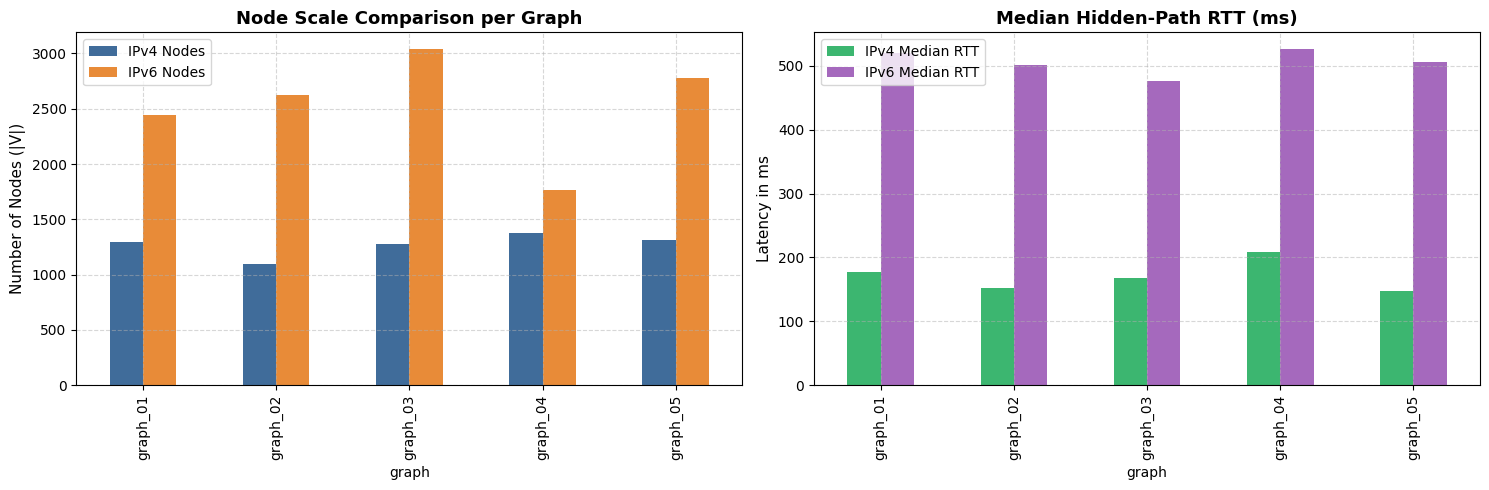

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# 1. Node count comparison
node_comp = pd.DataFrame({
    'IPv4 Nodes': df_v4_desc['nodes'].values,
    'IPv6 Nodes': df_v6_desc['nodes'].values,
}, index=df_v4_desc['graph'])
node_comp.plot(kind='bar', ax=axes[0], color=['#2b5c8f', '#e67e22'], alpha=0.9)
axes[0].set_title('Node Scale Comparison per Graph', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Nodes (|V|)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
# 2. Median RTT comparison
rtt_comp = pd.DataFrame({
    'IPv4 Median RTT': df_v4_desc['median_rtt_ms'].values,
    'IPv6 Median RTT': df_v6_desc['median_rtt_ms'].values,
}, index=df_v4_desc['graph'])
rtt_comp.plot(kind='bar', ax=axes[1], color=['#27ae60', '#9b59b6'], alpha=0.9)
axes[1].set_title('Median Hidden-Path RTT (ms)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Latency in ms', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
